# Supplementary figure: Table 2's models on two example cells and across the population

Builds the supplementary figure that goes with the manuscript's Table 2 (hoefling_2024): the test-set predictions of
eight models for an example slow ON cell (a linear cell) and an example OFF cell (a nonlinear cell), and the FEVe of
each model across the population.

| family | models | source |
|---|---|---|
| **low-res cascade models** (18x16 px) | greyscale LN, colour LN, Spatial Contrast | the lag-30 models of `compare_hoefling_2024_sc_lnp_grey.ipynb` (local runs in `openretina_assets/runs`) |
| **low-res networks** (18x16 px) | greyscale CNN, colour CNN, GRU | Table 2's checkpoints (HuggingFace, `model_checkpoints/2026-03-09`) |
| **high-res networks** (72x64 px) | colour CNN, GRU | Table 2's checkpoints |

Metrics follow Table 2: cells whose explainable/total variance is at least 0.15, FEVe clipped at 0 per cell, and every
model predicting from frame 30 of the test movie on (lag 30). The example cells are those of the comparison notebook:
per functional type, the cell whose FEVe in the greyscale LN model is closest to the type's 90th percentile.

The five network checkpoints (about 94 MB) are downloaded to the openretina cache (`~/openretina_cache` by default)
when they are first loaded.

# Setup

In [1]:
import os
import warnings
from pathlib import Path

import hydra
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from einops import rearrange
from matplotlib import patheffects
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator

from openretina.data_io.hoefling_2024.dataloaders import natmov_dataloaders_v2
from openretina.data_io.hoefling_2024.responses import filter_responses, make_final_responses
from openretina.data_io.hoefling_2024.stimuli import movies_from_pickle
from openretina.eval.metrics import correlation_numpy, explainable_vs_total_var, feve
from openretina.models.colour_gaussian_ln import ColourGaussianLNCoreReadout
from openretina.models.core_readout import load_core_readout_model
from openretina.models.spatial_contrast import SpatialContrastCoreReadout
from openretina.utils.file_utils import get_cache_directory, get_local_file_path
from openretina.utils.h5_handling import load_h5_into_dict

# Lightning repeats this for every checkpoint of a core-readout model; it is about how the checkpoints were saved
warnings.filterwarnings("ignore", message=r"Attribute '\w+' is an instance of `nn.Module`")

# Print sizes: Arial at 7 pt, thin lines, fonts embedded as text in the PDF
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
        "font.size": 7,
        "axes.labelsize": 7,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "legend.fontsize": 7,
        "axes.linewidth": 0.6,
        "xtick.major.width": 0.6,
        "ytick.major.width": 0.6,
        "xtick.major.size": 2.5,
        "ytick.major.size": 2.5,
        "xtick.minor.size": 1.2,
        "ytick.minor.size": 1.2,
        "xtick.minor.width": 0.6,
        "ytick.minor.width": 0.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",
    }
)

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

## Configuration

Models are given as `(kind, location, resolution)`. `kind` is `"sc"` (a `SpatialContrastCoreReadout`, which with its
contrast weight fixed at 0 is the greyscale LN model), `"lnc"` (a `ColourGaussianLNCoreReadout`) or `"net"` (loaded
with `load_core_readout_model`). A location that is a directory is searched for the `*_final.ckpt` written after
testing.

In [2]:
REPO = Path("..").resolve()
RUNS = REPO / "openretina_assets" / "runs"
FIGURE_DIRECTORY = REPO / "openretina_assets" / "figures"
HF_CHECKPOINTS = "https://huggingface.co/datasets/open-retina/open-retina/tree/main/model_checkpoints/2026-03-09"
HIRES_MOVIES = (
    "https://huggingface.co/datasets/open-retina/open-retina/blob/main/euler_lab/hoefling_2024/stimuli/"
    "rgc_natstim_72x64_joint_normalized_2024-10-11.zip"
)

# In the order of the figure: low-res cascade models, low-res networks, high-res networks
MODELS: dict[str, tuple[str, str | Path, str]] = {
    "Greyscale LN": ("sc", RUNS / "selection_v4" / "ln_t31_s15_tsmooth1e3" / "val_loss", "low"),
    "Colour LN": ("lnc", RUNS / "selection_v6" / "lnc_t31_s15_tsmooth1e3" / "val_loss", "low"),
    "Spatial Contrast": ("sc", RUNS / "selection_v4" / "sc_t31_s15_tsmooth1e3" / "val_loss_e600", "low"),
    "Greyscale CNN, low res": ("net", f"{HF_CHECKPOINTS}/hoefling_2024_cnn_low_res_grey_scale.ckpt", "low"),
    "Colour CNN, low res": ("net", f"{HF_CHECKPOINTS}/hoefling_2024_cnn_low_res.ckpt", "low"),
    "GRU, low res": ("net", f"{HF_CHECKPOINTS}/hoefling_2024_gru_low_res.ckpt", "low"),
    "Colour CNN, high res": ("net", f"{HF_CHECKPOINTS}/hoefling_2024_cnn_high_res.ckpt", "high"),
    "GRU, high res": ("net", f"{HF_CHECKPOINTS}/hoefling_2024_gru_high_res.ckpt", "high"),
}
# Table 2 as published (Avg, FEVe), to check that the networks are evaluated the same way
PUBLISHED_TABLE2 = {
    "Greyscale CNN, low res": (0.550, 0.386),
    "Colour CNN, low res": (0.549, 0.413),
    "GRU, low res": (0.585, 0.422),
    "Colour CNN, high res": (0.578, 0.450),
    "GRU, high res": (0.587, 0.445),
}

# Baden et al., 2016 functional types: (first group, last group)
GROUPS = {"OFF": (1, 9), "ON-OFF": (10, 14), "fast ON": (15, 20), "slow ON": (21, 28), "uncertain": (29, 32)}
MIN_EXPLAINABLE_VARIANCE_RATIO = 0.15
# Example cells as in the comparison notebook: per type, the reliable cell whose FEVe in EXAMPLE_MODEL is closest to
# the type's EXAMPLE_QUANTILE
EXAMPLE_MODEL = "Greyscale LN"
EXAMPLE_QUANTILE = 0.9
FRAME_RATE_HZ = 30

# Figure
FIGURE_WIDTH_MM, FIGURE_HEIGHT_MM = 142, 135
# Model -> (family, short name, colour); families light to dark
MODEL_STYLES = {
    "Greyscale LN": ("Low-Res cascade models", "Greyscale LN", "#83d494"),
    "Colour LN": ("Low-Res cascade models", "Colour LN", "#3da671"),
    "Spatial Contrast": ("Low-Res cascade models", "Spatial Contrast", "#007653"),
    "Greyscale CNN, low res": ("Low-Res networks", "Greyscale CNN", "#e89635"),
    "Colour CNN, low res": ("Low-Res networks", "Colour CNN", "#cf511e"),
    "GRU, low res": ("Low-Res networks", "GRU", "#701e20"),
    "Colour CNN, high res": ("High-Res networks", "Colour CNN", "#51a3e0"),
    "GRU, high res": ("High-Res networks", "GRU", "#2953a5"),
}
FAMILIES = list(dict.fromkeys(family for family, _, _ in MODEL_STYLES.values()))
RECORDED_COLOUR, RECORDED_EDGE = "#ebebeb", "#bdbdbd"
EXAMPLE_PANELS = {"slow ON": "Slow ON", "OFF": "OFF"}

device = "cuda" if torch.cuda.is_available() else "cpu"

## Data

The responses, quality-filtered as in training, and the test movie of every session at both resolutions (mirrored for
left eyes, as in training). The high-resolution dataloaders hold the training movies too (about 20 GB), so only their
test movies are kept.

In [3]:
with hydra.initialize(config_path=os.path.join("..", "configs"), version_base="1.3"):
    cfg = hydra.compose(config_name="hoefling_2024_core_readout_low_res_lnp_grey.yaml")

CACHE_DIR = os.environ.get("OPENRETINA_CACHE_DIRECTORY") or get_cache_directory()
cfg.paths.cache_dir = CACHE_DIR
os.environ["OPENRETINA_CACHE_DIRECTORY"] = CACHE_DIR

responses_dict = load_h5_into_dict(
    file_path=get_local_file_path(file_path=cfg.paths.responses_path, cache_folder=cfg.paths.data_dir)
)
final_responses = make_final_responses(filter_responses(responses_dict, **cfg.quality_checks), response_type="natural")
sessions = sorted(final_responses)


def test_movies_from(movies_path: str) -> dict[str, torch.Tensor]:
    dataloaders = natmov_dataloaders_v2(
        neuron_data_dictionary=final_responses,
        movies_dictionary=movies_from_pickle(
            get_local_file_path(file_path=movies_path, cache_folder=cfg.paths.data_dir)
        ),
        allow_over_boundaries=True,
        batch_size=cfg.dataloader.batch_size,
        train_chunk_size=cfg.dataloader.train_chunk_size,
        validation_clip_indices=cfg.dataloader.validation_clip_indices,
    )
    return {session: dataloaders["test"][session].dataset.movies for session in sessions}


test_movies = {"low": test_movies_from(cfg.paths.movies_path), "high": test_movies_from(HIRES_MOVIES)}
print(
    f"{sum(len(final_responses[s].session_kwargs['roi_ids']) for s in sessions)} neurons over {len(sessions)} sessions;"
    f" test movies {tuple(test_movies['low'][sessions[0]].shape)} and {tuple(test_movies['high'][sessions[0]].shape)}"
)

Loading HDF5 file contents:   0%|          | 0/2077 [00:00<?, ?item/s]

Original dataset contains 7863 neurons over 67 fields
 ------------------------------------ 


Dropped 0 fields that did not contain the target cell types (67 remaining)
Overall, dropped 3034 neurons of non-target cell types (-38.59%).
 ------------------------------------ 


Dropped 0 fields with quality indices below threshold (67 remaining)
Overall, dropped 980 neurons over quality checks (-20.29%).
 ------------------------------------ 


Dropped 0 fields with classifier confidences below 0.25
Overall, dropped 705 neurons with classifier confidences below 0.25 (-18.32%).
 ------------------------------------ 
 ------------------------------------ 
Final dataset contains 3144 neurons over 67 fields
Total number of cells dropped: 4719 (-60.02%)


Upsampling natural spikes traces to get final responses.:   0%|          | 0/67 [00:00<?, ?it/s]

Creating movie dataloaders:   0%|          | 0/67 [00:00<?, ?it/s]

Creating movie dataloaders:   0%|          | 0/67 [00:00<?, ?it/s]

3144 neurons over 67 sessions; test movies (2, 750, 18, 16) and (2, 750, 72, 64)


## Models and test metrics

Each model predicts the whole 750-frame test movie of every session at its own resolution. Correlation is computed
against the response averaged over the three repeats, FEVe against the individual repeats, both from frame 30 on.

In [4]:
def load_model(kind: str, location: str | Path):
    if kind == "net":
        model = load_core_readout_model(str(location), device)
    else:
        checkpoint = sorted(Path(location).glob("checkpoints/*_final.ckpt"))[-1]
        model_class = ColourGaussianLNCoreReadout if kind == "lnc" else SpatialContrastCoreReadout
        model = model_class.load_from_checkpoint(checkpoint, map_location=device, weights_only=False)
    assert set(model.readout.keys()) == set(sessions), f"{location} was trained on different sessions"
    return model.eval()


def test_metrics(model, movies: dict[str, torch.Tensor]) -> tuple[pd.DataFrame, dict[str, np.ndarray]]:
    # Per-cell test metrics of one model, and its test predictions per session (time, neurons)
    rows, model_predictions = [], {}
    for session in sessions:
        responses = final_responses[session]
        by_trial = responses.test_by_trial  # (neurons, time, trials)
        with torch.no_grad():
            prediction = model(movies[session].to(model.device).unsqueeze(0), data_key=session)
        prediction = prediction.squeeze(0).cpu().numpy()
        model_predictions[session] = prediction
        lag = by_trial.shape[1] - prediction.shape[0]

        targets = rearrange(by_trial, "neurons time trials -> time trials neurons")[lag:]
        explainable_ratio, _ = explainable_vs_total_var(targets)
        feve_per_neuron = feve(targets, prediction)
        corr_per_neuron = correlation_numpy(responses.test_response.T[lag:], prediction, axis=0)
        corr_per_trial = [correlation_numpy(targets[:, i], prediction, axis=0) for i in range(targets.shape[1])]
        for neuron in range(prediction.shape[1]):
            rows.append(
                {
                    "session": session,
                    "neuron": neuron,
                    "roi_id": int(responses.session_kwargs["roi_ids"][neuron]),
                    "group": int(responses.session_kwargs["group_assignment"][neuron]),
                    "lag": lag,
                    "explainable_ratio": explainable_ratio[neuron],
                    "correlation": corr_per_neuron[neuron],
                    **{f"correlation_trial_{i}": corr[neuron] for i, corr in enumerate(corr_per_trial)},
                    "feve": feve_per_neuron[neuron],
                }
            )
    cells = pd.DataFrame(rows)
    cells["reliable"] = cells["explainable_ratio"] >= MIN_EXPLAINABLE_VARIANCE_RATIO
    cells["group_class"] = pd.cut(
        cells["group"], bins=[0] + [last for _, last in GROUPS.values()], labels=list(GROUPS), include_lowest=True
    )
    return cells, model_predictions


parts, predictions, recurrent = [], {}, {}
for label, (kind, location, resolution) in MODELS.items():
    model = load_model(kind, location)
    if kind == "net" and "gru_kwargs" in model.hparams["core"]:
        # Whether the "GRU" checkpoints hold a recurrent module at all
        recurrent[label] = {
            "use_gru": model.hparams["core"].get("use_gru"),
            "recurrent weights": sum(v.numel() for k, v in model.state_dict().items() if "gru" in k.lower()),
        }
    cells, predictions[label] = test_metrics(model, test_movies[resolution])
    parts.append(cells.assign(model=label))
    del model
    torch.cuda.empty_cache()
metrics = pd.concat(parts, ignore_index=True)
assert metrics["lag"].nunique() == 1, "models cut different frames"
print(f"evaluated on frames {metrics['lag'].iloc[0]}..{final_responses[sessions[0]].test_by_trial.shape[1] - 1}")
pd.DataFrame(recurrent).T

evaluated on frames 30..749


,use_gru,recurrent weights
"GRU, low res",False,0
"GRU, high res",False,0


Table 2's two GRU checkpoints were trained with `use_gru: False`: their cores are the feed-forward part of
`ConvGRUCore` only, without the recurrent module. They keep their Table 2 name here.

The Table 2 numbers of the eight models: Avg (correlation with the trial average), Indiv (correlation with single
repeats, mean ± SD over the three repeats) and FEVe (clipped at 0 per cell), over the reliable cells. The networks'
rows are compared with Table 2 as published.

In [5]:
def table2_summary(cells: pd.DataFrame) -> dict:
    trials = cells[[c for c in cells.columns if c.startswith("correlation_trial_")]].mean()
    return {
        "Avg": cells["correlation"].mean(),
        "Indiv": f"{trials.mean():.3f} ± {trials.std(ddof=0):.3f}",
        "FEVe": cells["feve"].clip(lower=0).mean(),
        "cells at FEVe 0": (cells["feve"] <= 0).mean(),
    }


reliable = metrics[metrics["reliable"]]
table = pd.DataFrame({model: table2_summary(cells) for model, cells in reliable.groupby("model", sort=False)}).T
table = table.infer_objects()
table["published Avg"] = pd.Series({model: avg for model, (avg, _) in PUBLISHED_TABLE2.items()})
table["published FEVe"] = pd.Series({model: value for model, (_, value) in PUBLISHED_TABLE2.items()})
published = table.dropna(subset=["published Avg"])
# FEVe of the high-res GRU is 0.44449 here: it rounds to 0.444, against 0.445 published
assert (published["Avg"] - published["published Avg"]).abs().max() < 0.0006
assert (published["FEVe"] - published["published FEVe"]).abs().max() < 0.0006
cells_per_model = metrics.drop_duplicates(["session", "neuron"])
print(
    f"{cells_per_model['reliable'].sum()} of {len(cells_per_model)} cells have explainable/total variance"
    f" >= {MIN_EXPLAINABLE_VARIANCE_RATIO}"
)
table.round(3)

2408 of 3144 cells have explainable/total variance >= 0.15


,Avg,Indiv,FEVe,cells at FEVe 0,published Avg,published FEVe
Greyscale LN,0.394,0.314 ± 0.016,0.205,0.291,NaN,NaN
Colour LN,0.447,0.356 ± 0.018,0.245,0.282,NaN,NaN
Spatial Contrast,0.460,0.367 ± 0.015,0.288,0.159,NaN,NaN
"Greyscale CNN, low res",0.550,0.438 ± 0.014,0.386,0.118,0.550,0.386
"Colour CNN, low res",0.549,0.438 ± 0.018,0.413,0.082,0.549,0.413
"GRU, low res",0.585,0.466 ± 0.018,0.422,0.126,0.585,0.422
"Colour CNN, high res",0.578,0.460 ± 0.018,0.450,0.076,0.578,0.450
"GRU, high res",0.587,0.468 ± 0.018,0.444,0.100,0.587,0.445


## Example cells

The slow ON and OFF example cells of the comparison notebook, by the same rule.

In [6]:
reference = reliable[reliable["model"] == EXAMPLE_MODEL]
example_cells, example_rows = {}, []
for cell_type in EXAMPLE_PANELS:
    type_cells = reference[reference["group_class"] == cell_type]
    target = type_cells["feve"].quantile(EXAMPLE_QUANTILE)
    cell = type_cells.loc[(type_cells["feve"] - target).abs().idxmin()]
    example_cells[cell_type] = (cell["session"], int(cell["neuron"]), int(cell["roi_id"]), int(cell["group"]))
    scores = reliable[(reliable["session"] == cell["session"]) & (reliable["neuron"] == cell["neuron"])]
    example_rows.append(
        {"type": cell_type, "session": cell["session"], "roi": cell["roi_id"], "group": cell["group"]}
        | {f"FEVe, {model}": value for model, value in zip(scores["model"], scores["feve"])}
    )
assert example_cells["slow ON"][::2] == ("session_1_ventral1_20201030", 3)
assert example_cells["OFF"][::2] == ("session_3_ventral2_20210929", 42)

# Each example cell's trial-averaged test response and the eight models' predictions of it
traces = {
    cell_type: {"recorded": final_responses[session].test_by_trial[neuron].mean(axis=1)}
    | {label: predictions[label][session][:, neuron] for label in MODELS}
    for cell_type, (session, neuron, _, _) in example_cells.items()
}
pd.DataFrame(example_rows).set_index("type").round(3)

,session,roi,group,"FEVe, Greyscale LN","FEVe, Colour LN","FEVe, Spatial Contrast","FEVe, Greyscale CNN, low res","FEVe, Colour CNN, low res","FEVe, GRU, low res","FEVe, Colour CNN, high res","FEVe, GRU, high res"
type,,,,,,,,,,,
slow ON,session_1_ventral1_20201030,3,23,0.593,0.702,0.564,0.759,0.782,0.765,0.802,0.852
OFF,session_3_ventral2_20210929,42,5,0.289,0.573,0.529,0.763,0.711,0.824,0.840,0.787


## Figure

142 mm wide, the manuscript's text column. Saved as PDF (vector, fonts embedded) and PNG to
`openretina_assets/figures/`.

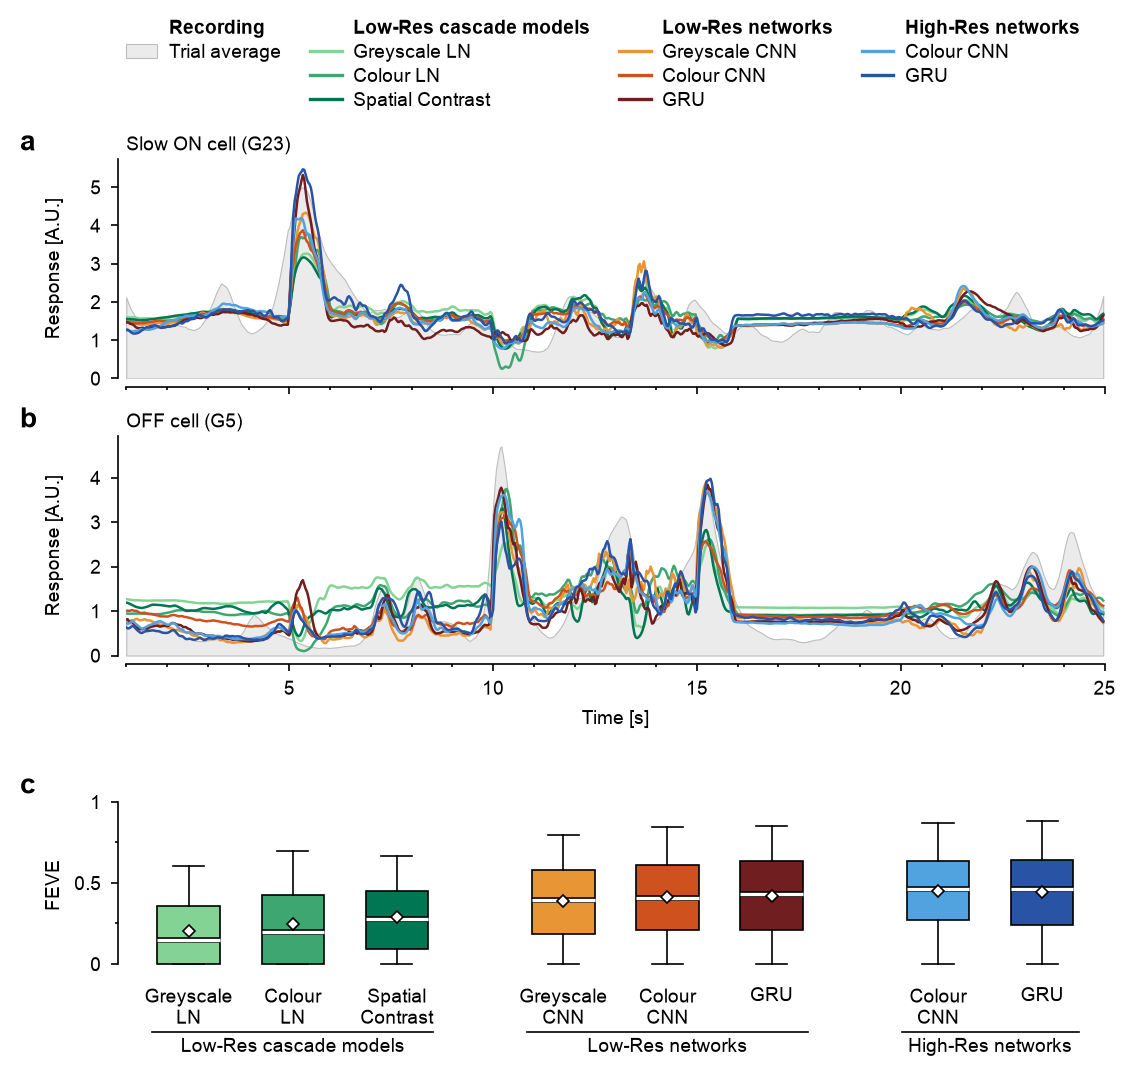

In [7]:
SPINE_OFFSET_PT = 3
LETTER_X = 0.005  # figure fraction: the letters sit at the figure's left edge, as in the manuscript's figures


def offset_spines(ax: plt.Axes) -> None:
    for side in ["left", "bottom"]:
        ax.spines[side].set_position(("outward", SPINE_OFFSET_PT))


def label_panel(fig: plt.Figure, ax: plt.Axes, letter: str, label: str = "") -> None:
    # The panel letter at the figure's left edge and an optional short label above the axes, on one baseline
    y = ax.get_position().y1 + 0.008
    fig.text(LETTER_X, y, letter, fontsize=10, fontweight="bold", va="baseline", ha="left")
    if label:
        fig.text(ax.get_position().x0, y, label, va="baseline", ha="left")


def points_to_axes(ax: plt.Axes, points: float) -> float:
    # A vertical distance in points as a fraction of the axes' height
    return points / (ax.get_position().height * ax.figure.get_figheight() * 72)


def make_figure() -> plt.Figure:
    fig = plt.figure(figsize=(FIGURE_WIDTH_MM / 25.4, FIGURE_HEIGHT_MM / 25.4))
    # Rows: a, b, a spacer for b's time axis, c
    grid = fig.add_gridspec(
        4, 1, height_ratios=[1.25, 1.25, 0.18, 0.95], hspace=0.36, left=0.1, right=0.975, top=0.862, bottom=0.1
    )
    trace_axes = [fig.add_subplot(grid[0])]
    trace_axes.append(fig.add_subplot(grid[1], sharex=trace_axes[0]))
    box_ax = fig.add_subplot(grid[3])

    # a, b: the example cells' test responses and predictions
    for ax, cell_type in zip(trace_axes, EXAMPLE_PANELS):
        cell_traces = traces[cell_type]
        recorded = cell_traces["recorded"]
        lag = len(recorded) - len(cell_traces["Greyscale LN"])
        time_s = np.arange(len(recorded)) / FRAME_RATE_HZ
        ax.fill_between(time_s[lag:], 0, recorded[lag:], facecolor=RECORDED_COLOUR, edgecolor=RECORDED_EDGE, lw=0.4)
        for label, (_, _, colour) in MODEL_STYLES.items():
            ax.plot(time_s[lag:], cell_traces[label], color=colour, lw=0.9)
        ax.set_xlim(time_s[lag], time_s[-1] + 1 / FRAME_RATE_HZ)
        ax.set_ylim(bottom=0)
        ax.yaxis.set_major_locator(MultipleLocator(1))
        ax.xaxis.set_minor_locator(MultipleLocator(1))
        ax.set_ylabel("Response [A.U.]")
        offset_spines(ax)
    trace_axes[0].tick_params(labelbottom=False)
    trace_axes[1].set_xticks(np.arange(5, 26, 5))
    trace_axes[1].set_xlabel("Time [s]")

    # c: FEVe across the reliable cells, clipped at 0 as in Table 2
    reliable = metrics[metrics["reliable"]]
    positions, position, previous_family = [], 0.0, None
    for family, _, _ in MODEL_STYLES.values():
        if previous_family is not None:
            position += 1.0 if family == previous_family else 1.6
        positions.append(position)
        previous_family = family
    values = [reliable.loc[reliable["model"] == label, "feve"].clip(lower=0).to_numpy() for label in MODEL_STYLES]
    boxes = box_ax.boxplot(
        values,
        positions=positions,
        widths=0.6,
        whis=(5, 95),
        patch_artist=True,
        showfliers=False,
        showmeans=True,
        medianprops={
            "color": "white",
            "lw": 1.2,
            "path_effects": [patheffects.withStroke(linewidth=2.0, foreground="k")],
        },
        whiskerprops={"color": "k", "lw": 0.6},
        capprops={"color": "k", "lw": 0.6},
        boxprops={"edgecolor": "k", "lw": 0.6},
        meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "k", "markersize": 3, "mew": 0.6},
    )
    for patch, (_, _, colour) in zip(boxes["boxes"], MODEL_STYLES.values()):
        patch.set_facecolor(colour)
    box_ax.set_xticks(positions, [short.replace(" ", "\n", 1) for _, short, _ in MODEL_STYLES.values()])
    box_ax.tick_params(axis="x", length=0)
    box_ax.set_xlim(positions[0] - 0.6, positions[-1] + 0.6)
    # A little room below 0, so that the whisker caps at FEVe = 0 are drawn in full; the spine still spans 0-1
    box_ax.set_ylim(-0.03, 1)
    box_ax.spines["left"].set_bounds(0, 1)
    box_ax.set_yticks([0, 0.5, 1], ["0", "0.5", "1"])
    box_ax.yaxis.set_minor_locator(MultipleLocator(0.25))
    box_ax.set_ylabel("FEVE")
    offset_spines(box_ax)
    box_ax.spines["bottom"].set_visible(False)
    transform = matplotlib.transforms.blended_transform_factory(box_ax.transData, box_ax.transAxes)
    for family in FAMILIES:
        family_positions = [p for p, (f, _, _) in zip(positions, MODEL_STYLES.values()) if f == family]
        left, right = family_positions[0] - 0.35, family_positions[-1] + 0.35
        # Below the two-line tick labels
        bracket = -points_to_axes(box_ax, 2 * 7 * 1.2 + 6)
        box_ax.plot([left, right], [bracket] * 2, color="k", lw=0.6, transform=transform, clip_on=False)
        box_ax.text(
            (left + right) / 2, bracket - points_to_axes(box_ax, 2), family, transform=transform, ha="center", va="top"
        )
    fig.align_ylabels([*trace_axes, box_ax])

    # Legend: the recording, then one column per family, starting at the axes' left edge
    blank = Line2D([], [], ls="", marker="")
    columns = [
        [(blank, "Recording"), (Patch(facecolor=RECORDED_COLOUR, edgecolor=RECORDED_EDGE, lw=0.4), "Trial average")]
    ]
    for family in FAMILIES:
        column = [(blank, family)]
        column += [
            (Line2D([], [], color=colour, lw=1.2), short) for f, short, colour in MODEL_STYLES.values() if f == family
        ]
        columns.append(column)
    rows = max(len(column) for column in columns)
    entries = [entry for column in columns for entry in column + [(blank, "")] * (rows - len(column))]
    legend = fig.legend(
        [handle for handle, _ in entries],
        [text for _, text in entries],
        ncols=len(columns),
        loc="upper left",
        bbox_to_anchor=(trace_axes[0].get_position().x0, 0.993),
        frameon=False,
        borderpad=0,
        borderaxespad=0,
        handlelength=1.6,
        handletextpad=0.6,
        columnspacing=1.5,
        labelspacing=0.3,
    )
    headers = {"Recording", *FAMILIES}
    for text in legend.get_texts():
        if text.get_text() in headers:
            text.set_fontweight("bold")

    for ax, letter, (cell_type, name) in zip(trace_axes, "ab", EXAMPLE_PANELS.items()):
        label_panel(fig, ax, letter, f"{name} cell (G{example_cells[cell_type][3]})")
    label_panel(fig, box_ax, "c")
    return fig


figure = make_figure()
FIGURE_DIRECTORY.mkdir(parents=True, exist_ok=True)
for suffix, options in [("pdf", {}), ("png", {"dpi": 600})]:
    figure.savefig(FIGURE_DIRECTORY / f"supplementary_model_predictions.{suffix}", **options)
plt.show()

## Caption

**Figure 6. Predictions of the Table 2 models for two example cells, and their performance across the population.**
**(a)** Predicted responses of the eight models of Table 2 to the test movie for an example slow ON cell (group 23,
ON mini alpha; Baden et al., 2016), overlaid on the cell's response averaged over the three test repeats (grey).
Greens: low-resolution cascade models (greyscale LN, colour LN, Spatial Contrast); oranges: low-resolution networks
(greyscale CNN, colour CNN, GRU); blues: high-resolution networks (colour CNN, GRU). The traces start at 1 s: the
first second of the test movie, which every model consumes before its first prediction (a time lag of 30 frames), is
not shown. **(b)** Same as
(a), for an example OFF cell (group 5, OFF alpha sustained). In each functional type, the example is the cell whose
FEVE under the greyscale LN model is closest to the type's 90th percentile, i.e. a cell that all models fit well.
**(c)** FEVE of each model across the 2,408 cells with an explainable-to-total variance ratio of at least 0.15, the
cells of Table 2. As in Table 2, FEVE is clipped at 0 per cell; 29%, 28% and 16% of the cells are at 0 for the three
cascade models, and 8–13% for the networks. Boxes: quartiles; white line: median; diamond: mean, the FEVE of Table 2;
whiskers: 5th to 95th percentiles; cells beyond the whiskers are not shown. Low-res: 18 × 16 pixels of 50 µm; high-res: 72 × 64 pixels of 12.5 µm.